📷 1º passo: envie o RETRATO de João Ribeiro da Silveira


Saving WhatsApp Image 2026-10-01 at 09.20.38.jpeg to WhatsApp Image 2026-10-01 at 09.20.38 (1).jpeg
🏫 2º passo: envie a FOTO DA ESCOLA


Saving WhatsApp Image 2026-10-07 at 16.45.25.jpeg to WhatsApp Image 2026-10-07 at 16.45.25 (1).jpeg
🏀 3º passo: envie as FOTOS DA REFORMA DA QUADRA
Você pode selecionar várias fotos de uma vez ou enviar um arquivo ZIP.


Saving 89b158b9-6585-42f0-b30c-5ed89c485cea.png to 89b158b9-6585-42f0-b30c-5ed89c485cea.png



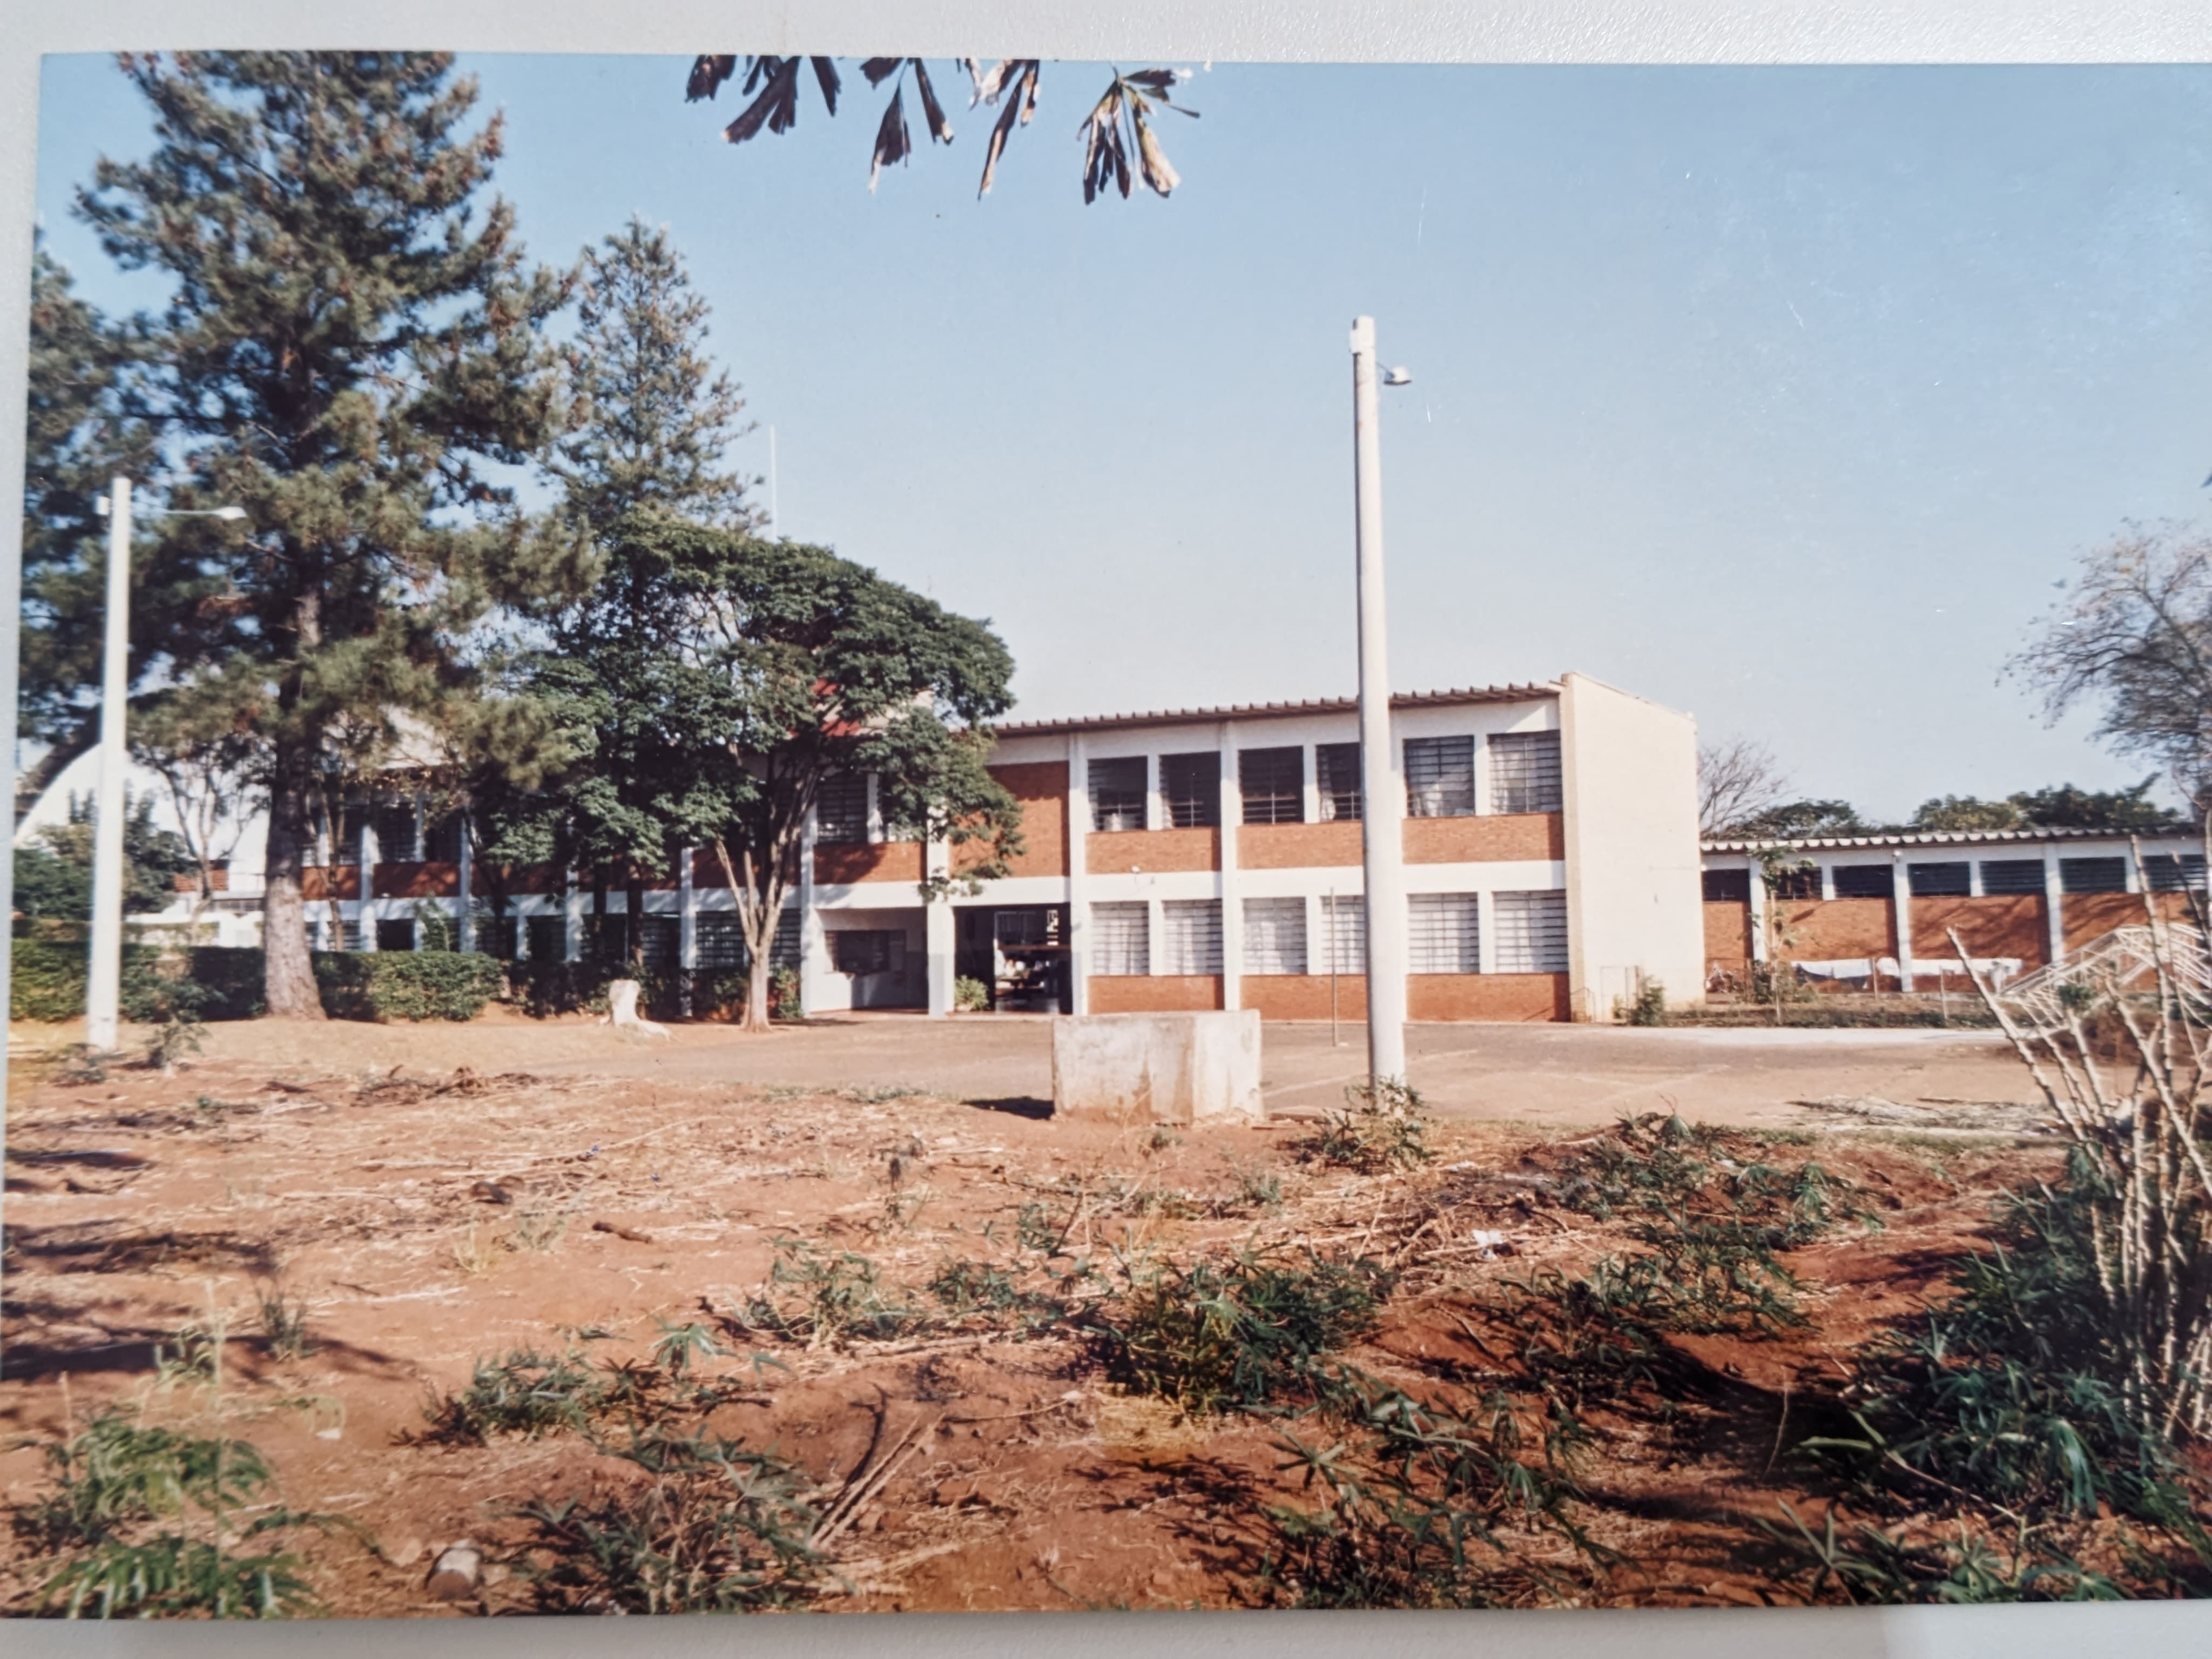
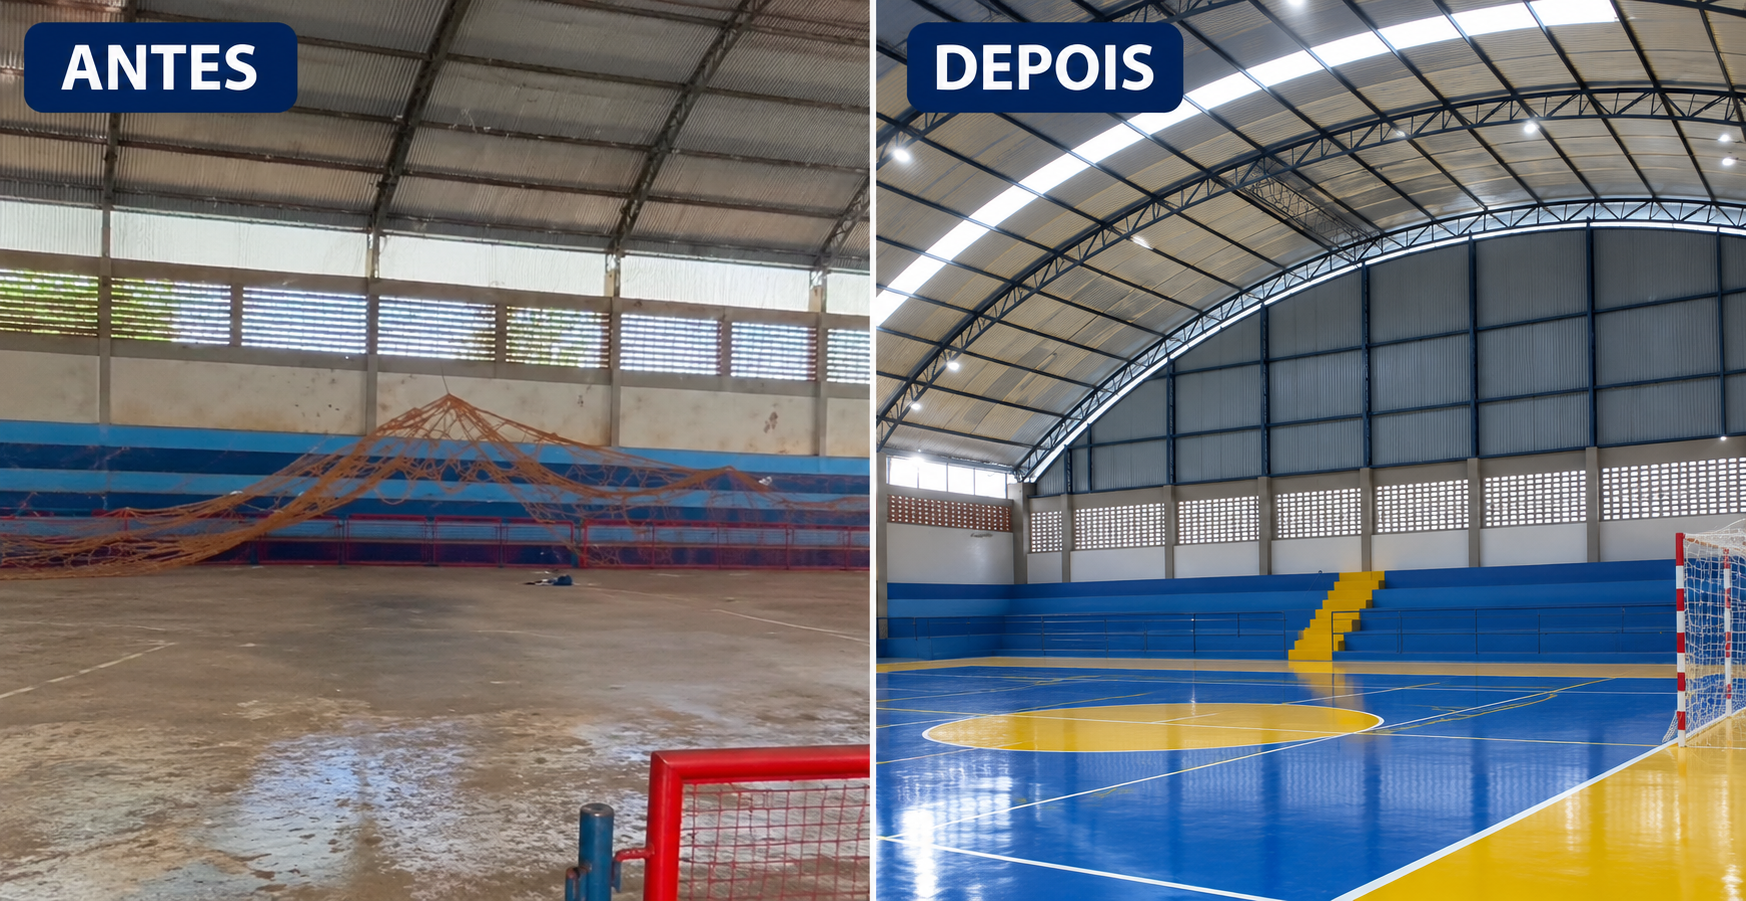
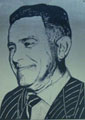
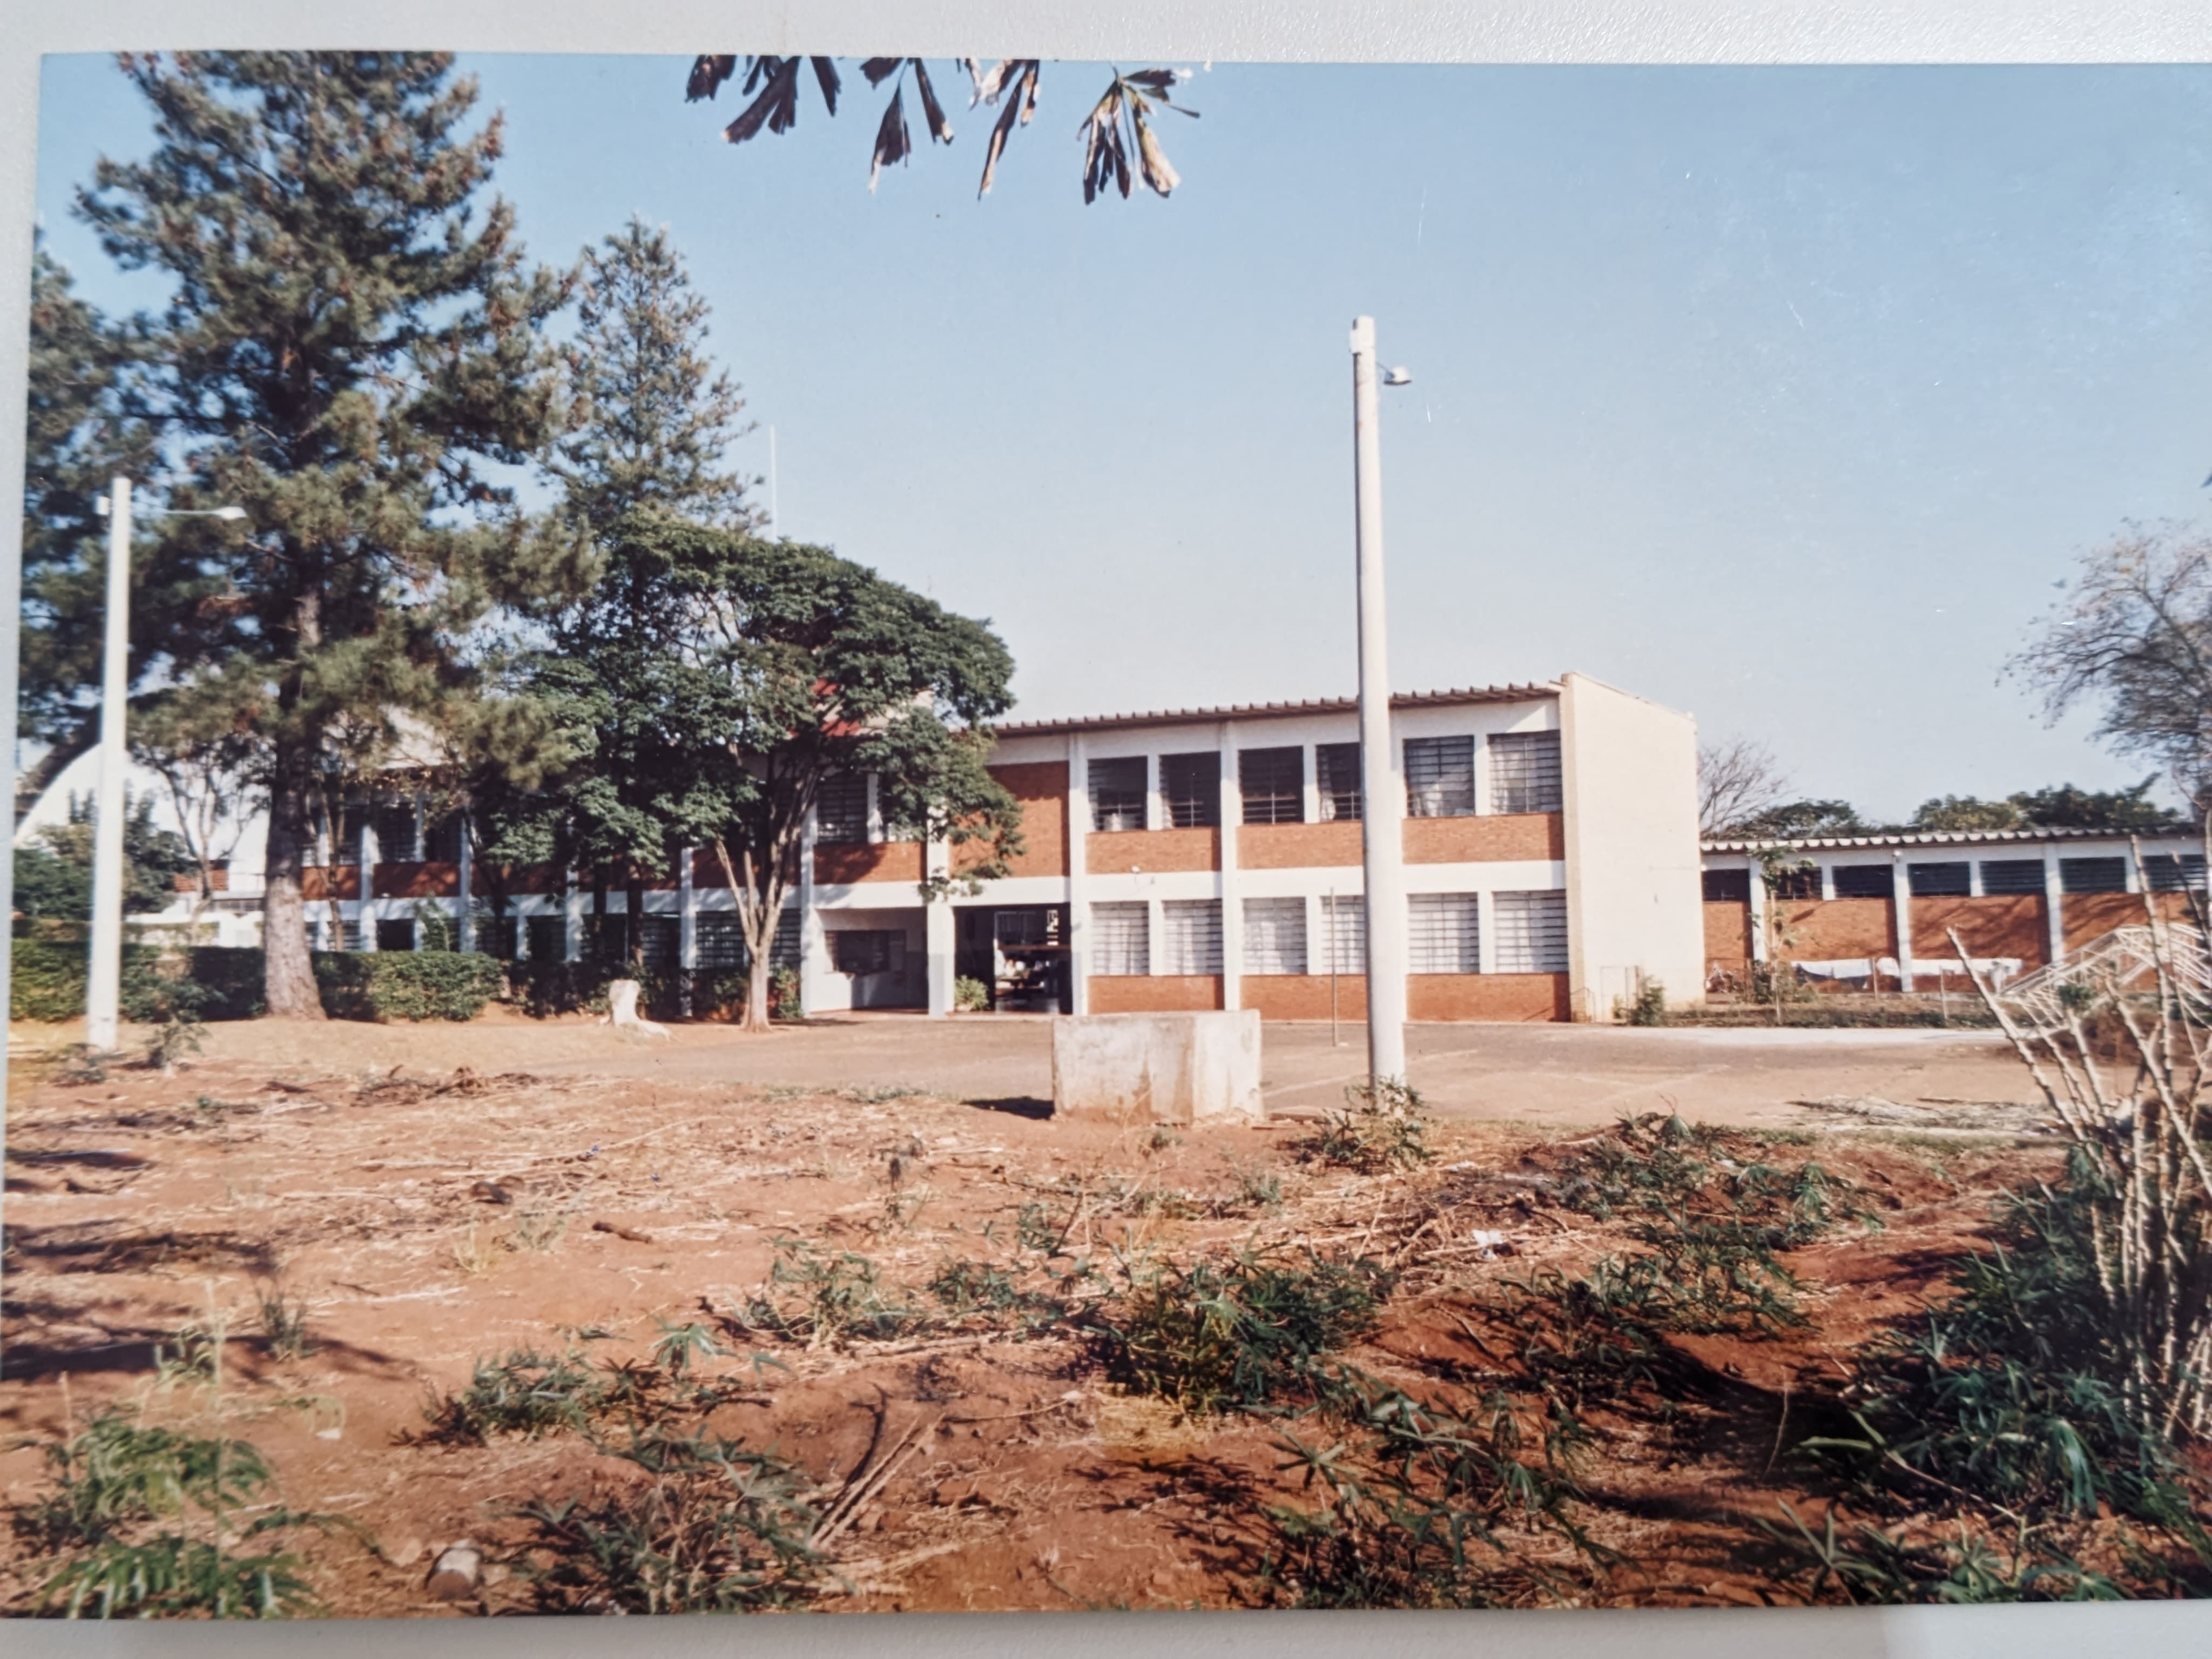
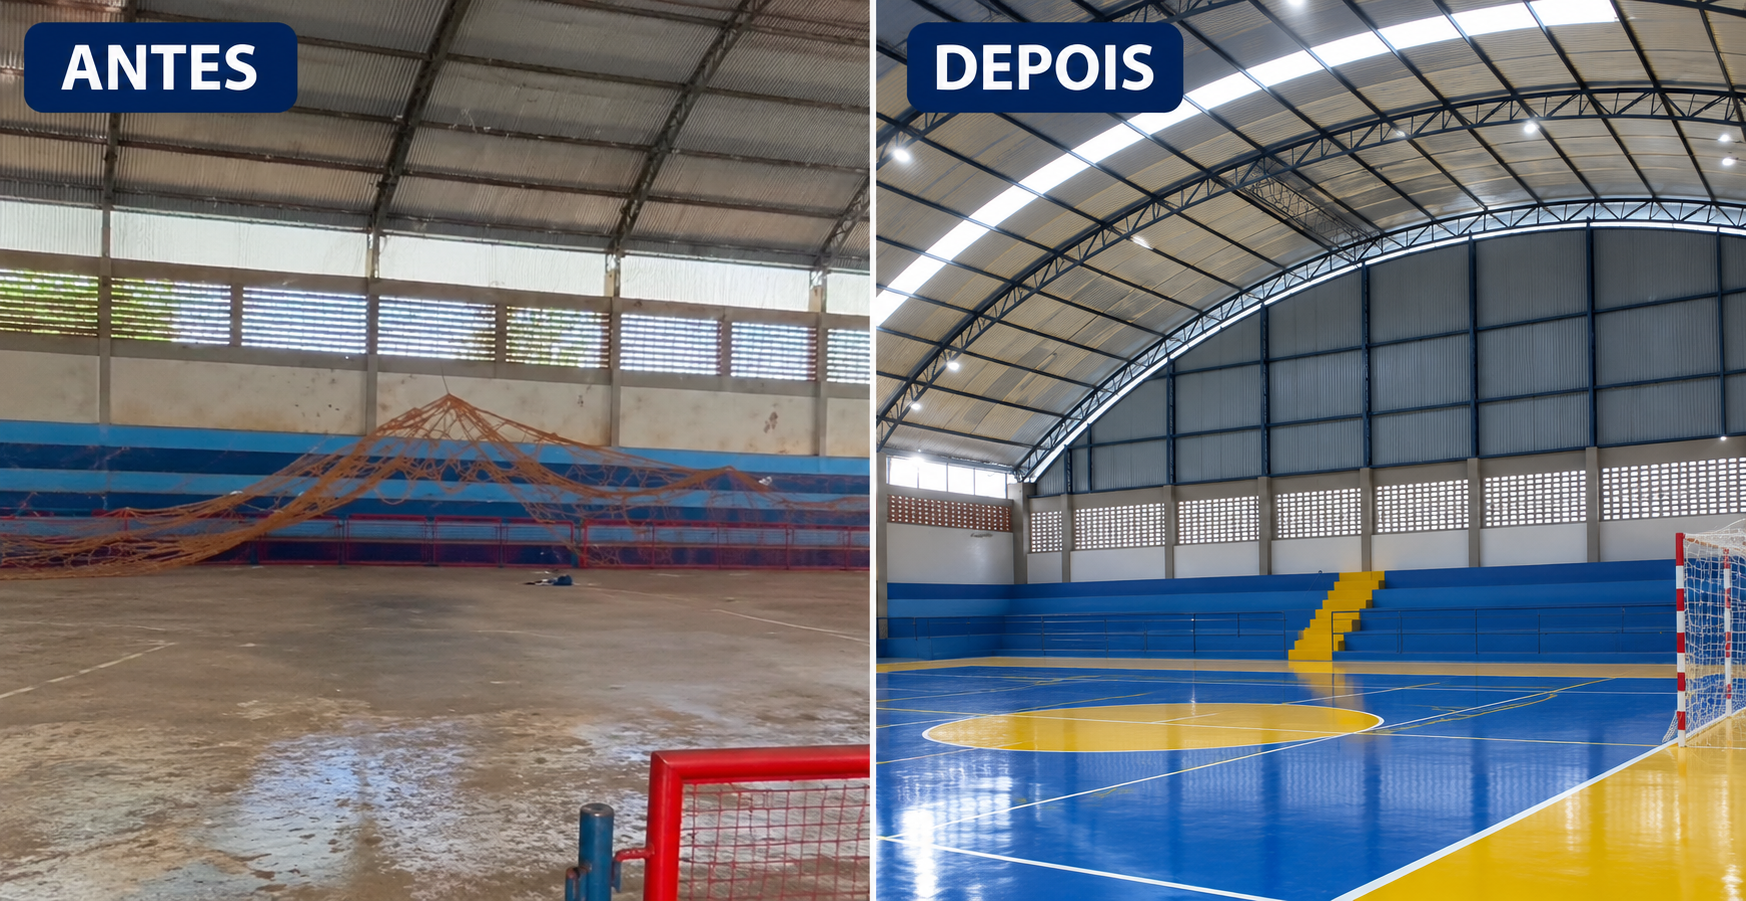

✅ Site completo carregado!
🏛️ Página 1: João Ribeiro da Silveira
🏀 Página 2: Reforma da Quadra


In [3]:
# ============================================================
# SITE HISTÓRICO DE ICÉM - 2 PÁGINAS EM UMA ÚNICA CÉLULA
# Página 1: João Ribeiro da Silveira
# Página 2: Reforma da Quadra da Escola
# ============================================================

from google.colab import files
from IPython.display import HTML, display
import base64
import mimetypes
import zipfile
import os
import tempfile

# ------------------------------------------------------------
# FUNÇÃO PARA TRANSFORMAR IMAGEM EM BASE64
# ------------------------------------------------------------

def converter_imagem(nome):
    with open(nome, "rb") as f:
        dados = f.read()

    mime, _ = mimetypes.guess_type(nome)

    if not mime:
        mime = "image/jpeg"

    base64_img = base64.b64encode(dados).decode("utf-8")
    return f"data:{mime};base64,{base64_img}"


# ============================================================
# 1ª PÁGINA
# ============================================================

print("📷 1º passo: envie o RETRATO de João Ribeiro da Silveira")
upload_retrato = files.upload()

nome_retrato = list(upload_retrato.keys())[0]
retrato = converter_imagem(nome_retrato)


print("🏫 2º passo: envie a FOTO DA ESCOLA")
upload_escola = files.upload()

nome_escola = list(upload_escola.keys())[0]
escola = converter_imagem(nome_escola)


# ============================================================
# 2ª PÁGINA - FOTOS DA REFORMA
# ============================================================

print("🏀 3º passo: envie as FOTOS DA REFORMA DA QUADRA")
print("Você pode selecionar várias fotos de uma vez ou enviar um arquivo ZIP.")

upload_quad = files.upload()

imagens_quad = []

temp_dir = tempfile.mkdtemp()

for nome, dados in upload_quad.items():

    caminho = os.path.join(temp_dir, nome)

    with open(caminho, "wb") as f:
        f.write(dados)

    # Se for ZIP
    if nome.lower().endswith(".zip"):

        pasta_zip = os.path.join(
            temp_dir,
            os.path.splitext(nome)[0]
        )

        os.makedirs(pasta_zip, exist_ok=True)

        with zipfile.ZipFile(caminho, "r") as zip_ref:
            zip_ref.extractall(pasta_zip)

        for raiz, diretorios, arquivos in os.walk(pasta_zip):

            for arquivo in arquivos:

                if arquivo.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".webp", ".gif")
                ):

                    caminho_img = os.path.join(raiz, arquivo)

                    imagens_quad.append(
                        converter_imagem(caminho_img)
                    )

    # Se for imagem normal
    elif nome.lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp", ".gif")
    ):

        imagens_quad.append(
            converter_imagem(caminho)
        )


# Caso nenhuma foto seja enviada
if not imagens_quad:
    imagens_quad = [escola]


# ============================================================
# GALERIA DA SEGUNDA PÁGINA
# ============================================================

galeria = ""

for imagem in imagens_quad:

    galeria += f"""
    <div class="foto-card">
        <img src="{imagem}">
    </div>
    """


# Primeira foto como imagem principal da segunda página
foto_capa_quad = imagens_quad[0]


# ============================================================
# HTML COMPLETO
# ============================================================

html = f"""

<!DOCTYPE html>

<html lang="pt-BR">

<head>

<meta charset="UTF-8">

<meta name="viewport"
content="width=device-width, initial-scale=1.0">

<title>Memória de Icém - João Ribeiro da Silveira</title>


<style>

* {{
    box-sizing: border-box;
    margin: 0;
    padding: 0;
}}

html {{
    scroll-behavior: smooth;
}}

body {{
    background: #f4f0e8;
    color: #263238;
    font-family: Arial, sans-serif;
    line-height: 1.7;
}}


/* =========================================================
   MENU
========================================================= */

.menu {{
    position: sticky;
    top: 0;
    z-index: 999;

    background: #182b35;

    display: flex;
    justify-content: center;
    align-items: center;

    gap: 15px;

    padding: 14px;

    box-shadow: 0 3px 10px rgba(0,0,0,0.25);

    flex-wrap: wrap;
}}

.menu button {{
    background: transparent;
    color: white;

    border: 1px solid rgba(255,255,255,0.35);

    padding: 10px 18px;

    border-radius: 25px;

    cursor: pointer;

    font-size: 14px;

    transition: 0.3s;
}}

.menu button:hover {{
    background: #d49a52;
    border-color: #d49a52;
}}


/* =========================================================
   PÁGINAS
========================================================= */

.pagina {{
    display: none;
}}

.pagina.ativa {{
    display: block;
}}


/* =========================================================
   HERO
========================================================= */

.hero {{
    min-height: 70vh;

    background:
        linear-gradient(
            rgba(24,43,53,0.75),
            rgba(24,43,53,0.75)
        ),
        url("{escola}");

    background-size: cover;
    background-position: center;

    display: flex;
    align-items: center;
    justify-content: center;

    text-align: center;

    padding: 50px 20px;

    color: white;
}}

.hero h1 {{
    font-family: Georgia, serif;

    font-size: clamp(38px, 7vw, 78px);

    margin-bottom: 20px;
}}

.hero p {{
    max-width: 800px;

    margin: auto;

    font-size: 18px;
}}


/* =========================================================
   CONTAINER
========================================================= */

.container {{
    width: min(1100px, 92%);

    margin: auto;
}}

section {{
    padding: 75px 0;
}}

h2 {{
    font-family: Georgia, serif;

    color: #182b35;

    font-size: 38px;

    margin-bottom: 30px;
}}

h3 {{
    color: #182b35;
}}


/* =========================================================
   BOTÕES
========================================================= */

.botao {{
    display: inline-block;

    margin-top: 25px;

    background: #b66d38;

    color: white;

    border: none;

    padding: 13px 25px;

    border-radius: 25px;

    cursor: pointer;

    text-decoration: none;

    font-weight: bold;
}}

.botao:hover {{
    background: #8e5129;
}}


/* =========================================================
   BIOGRAFIA
========================================================= */

.bio {{
    display: grid;

    grid-template-columns: 300px 1fr;

    gap: 50px;

    align-items: center;
}}

.bio img {{
    width: 100%;

    border-radius: 10px;

    box-shadow:
        0 10px 30px rgba(0,0,0,0.2);
}}

.texto p {{
    margin-bottom: 18px;
}}


/* =========================================================
   CARDS
========================================================= */

.cards {{
    display: grid;

    grid-template-columns:
        repeat(auto-fit, minmax(230px, 1fr));

    gap: 25px;
}}

.card {{
    background: white;

    padding: 30px;

    border-radius: 12px;

    box-shadow:
        0 5px 20px rgba(0,0,0,0.08);

    border-top: 4px solid #d49a52;
}}

.card h3 {{
    margin-bottom: 12px;

    font-family: Georgia, serif;
}}


/* =========================================================
   LINHA DO TEMPO
========================================================= */

.timeline {{
    border-left: 4px solid #d49a52;

    padding-left: 30px;
}}

.timeline-item {{
    background: white;

    padding: 25px;

    margin-bottom: 25px;

    border-radius: 10px;

    box-shadow:
        0 5px 15px rgba(0,0,0,0.08);
}}


/* =========================================================
   IMAGEM ESCOLA
========================================================= */

.escola-img {{
    width: 100%;

    max-height: 600px;

    object-fit: cover;

    border-radius: 12px;

    box-shadow:
        0 10px 30px rgba(0,0,0,0.18);
}}


/* =========================================================
   CITAÇÃO
========================================================= */

.citacao {{
    background: #182b35;

    color: white;

    padding: 50px;

    border-radius: 15px;

    text-align: center;

    margin: 40px 0;
}}

.citacao p {{
    font-family: Georgia, serif;

    font-size: 23px;

    font-style: italic;
}}


/* =========================================================
   PÁGINA 2
========================================================= */

.hero-quadra {{
    min-height: 70vh;

    background:
        linear-gradient(
            rgba(24,43,53,0.68),
            rgba(24,43,53,0.68)
        ),
        url("{foto_capa_quad}");

    background-size: cover;

    background-position: center;

    display: flex;

    align-items: center;

    justify-content: center;

    text-align: center;

    color: white;

    padding: 60px 20px;
}}

.hero-quadra h1 {{
    font-family: Georgia, serif;

    font-size: clamp(36px, 6vw, 70px);

    margin-bottom: 20px;
}}


.relato {{
    background: white;

    padding: 40px;

    border-radius: 15px;

    box-shadow:
        0 5px 25px rgba(0,0,0,0.08);
}}

.relato p {{
    margin-bottom: 20px;
}}


.destaque {{
    background: #d49a52;

    color: white;

    padding: 45px;

    border-radius: 15px;

    margin: 40px 0;

    text-align: center;
}}

.destaque h2 {{
    color: white;
}}

.destaque p {{
    font-size: 20px;
}}


/* =========================================================
   GALERIA
========================================================= */

.galeria {{
    display: grid;

    grid-template-columns:
        repeat(auto-fit, minmax(250px, 1fr));

    gap: 20px;

    margin-top: 30px;
}}

.foto-card {{
    overflow: hidden;

    border-radius: 12px;

    background: white;

    box-shadow:
        0 5px 18px rgba(0,0,0,0.12);

    min-height: 230px;
}}

.foto-card img {{
    width: 100%;

    height: 280px;

    object-fit: cover;

    display: block;

    transition: transform 0.4s;
}}

.foto-card img:hover {{
    transform: scale(1.05);
}}


/* =========================================================
   RODAPÉ
========================================================= */

footer {{
    background: #182b35;

    color: white;

    text-align: center;

    padding: 40px 20px;

    margin-top: 50px;
}}


/* =========================================================
   RESPONSIVO
========================================================= */

@media(max-width: 700px) {{

    .bio {{
        grid-template-columns: 1fr;
    }}

    .bio img {{
        max-width: 350px;

        margin: auto;
    }}

    section {{
        padding: 50px 0;
    }}

    h2 {{
        font-size: 30px;
    }}

    .relato {{
        padding: 25px;
    }}

    .citacao {{
        padding: 30px 20px;
    }}

}}

</style>

</head>


<body>


<!-- ========================================================
MENU PRINCIPAL
======================================================== -->

<div class="menu">

<button onclick="mostrarPagina('pagina1')">
🏛️ João Ribeiro da Silveira
</button>

<button onclick="mostrarPagina('pagina2')">
🏀 Reforma da Quadra
</button>

</div>



<!-- ========================================================
PÁGINA 1
======================================================== -->

<div id="pagina1" class="pagina ativa">


<div class="hero">

<div>

<h1>
João Ribeiro da Silveira
</h1>

<p>
Memória, história e legado de uma importante figura
da história de Icém – São Paulo.
</p>

<button
class="botao"
onclick="document.getElementById('biografia').scrollIntoView()">

Conhecer a história

</button>

</div>

</div>



<section id="biografia">

<div class="container">

<h2>
Biografia
</h2>

<div class="bio">

<img src="{retrato}">

<div class="texto">

<p>
João Ribeiro da Silveira foi prefeito de Icém,
participando de momentos importantes da história
administrativa e educacional do município.
</p>

<p>
Seu nome permanece presente na memória da cidade
e também está relacionado à história da Escola
João Ribeiro da Silveira.
</p>

<p>
Entre os períodos registrados de sua atuação política,
estão os mandatos de <strong>1963 a 1966</strong> e
de <strong>novembro de 1972 a janeiro de 1973</strong>.
</p>

<p>
Seu segundo período à frente da Prefeitura foi
interrompido em janeiro de 1973, com seu falecimento.
</p>

</div>

</div>

</div>

</section>



<section>

<div class="container">

<h2>
Mandatos
</h2>

<div class="timeline">

<div class="timeline-item">

<h3>
1963 – 1966
</h3>

<p>
Primeiro período de João Ribeiro da Silveira
à frente da Prefeitura Municipal de Icém.
</p>

</div>


<div class="timeline-item">

<h3>
Novembro de 1972 – Janeiro de 1973
</h3>

<p>
Retorno ao cargo de prefeito, em um segundo
período administrativo que terminou em janeiro
de 1973.
</p>

</div>

</div>

</div>

</section>



<section>

<div class="container">

<h2>
Legado
</h2>

<div class="cards">

<div class="card">

<h3>
Prefeitura Municipal
</h3>

<p>
Sua trajetória está ligada à história política
e administrativa de Icém.
</p>

</div>


<div class="card">

<h3>
Educação
</h3>

<p>
Seu nome permanece relacionado à história
da educação municipal por meio da escola
que recebeu seu nome.
</p>

</div>


<div class="card">

<h3>
História
</h3>

<p>
Sua memória faz parte da identidade histórica
do município de Icém.
</p>

</div>

</div>

</div>

</section>



<section>

<div class="container">

<h2>
Escola João Ribeiro da Silveira
</h2>

<img
src="{escola}"
class="escola-img"
>

<br>

<p style="margin-top:25px;">

A antiga EMEF João Ribeiro da Silveira,
localizada na Avenida Isaac Alves Ferreira,
450, fez parte da história da educação municipal.

</p>

<p style="margin-top:15px;">

A unidade funcionou no prédio que atualmente
é utilizado pela rede estadual de ensino.
Em 2014 ocorreu a mudança para outra unidade,
que posteriormente recebeu o nome de
EMEF Professora Maria Rezende de Moraes.

</p>

<p style="margin-top:15px;">

A nova unidade foi inaugurada em
<strong>5 de fevereiro de 2016</strong>.
</p>

</div>

</section>



<section>

<div class="container">

<div class="citacao">

<p>
"Uma cidade também preserva sua história
através dos nomes, lugares e pessoas que
fizeram parte de sua trajetória."
</p>

</div>

</div>

</section>



<section>

<div class="container">

<h2>
Endereço
</h2>

<p>
<strong>
Rua Prefeito João Ribeiro da Silveira, 550
</strong>
</p>

<p>
Centro – Icém/SP
</p>

</div>

</section>



<section>

<div class="container">

<h2>
Fontes
</h2>

<div class="cards">

<div class="card">
Prefeitura Municipal de Icém
</div>

<div class="card">
Diretoria Municipal de Educação
</div>

<div class="card">
Imprensa Oficial
</div>

<div class="card">
Câmara Municipal
</div>

</div>

</div>

</section>


<footer>

<p>
Memória de Icém
</p>

<p>
João Ribeiro da Silveira
</p>

</footer>

</div>



<!-- ========================================================
PÁGINA 2
======================================================== -->

<div id="pagina2" class="pagina">


<div class="hero-quadra">

<div>

<h1>
A Reforma da Quadra
</h1>

<p>
Escola João Ribeiro da Silveira
</p>

<button
class="botao"
onclick="document.getElementById('relato').scrollIntoView()">

Conhecer essa conquista

</button>

</div>

</div>



<section id="relato">

<div class="container">

<h2>
Uma conquista da comunidade escolar
</h2>


<div class="relato">

<p>
Como diretora da Escola João Ribeiro da Silveira,
vivi uma das conquistas mais importantes da nossa
comunidade escolar: a reforma da nossa quadra
poliesportiva.
</p>


<p>
Desde que assumi a direção da escola, percebi o
quanto a quadra precisava de melhorias. Era um
espaço muito importante para nossos alunos, não
apenas para as aulas de Educação Física, mas também
para os momentos de convivência, recreação, eventos
e atividades que fazem parte da vida escolar.
</p>


<p>
Ver aquele espaço precisando de cuidados sempre
foi uma preocupação para mim.
</p>


<p>
Por isso, comecei uma verdadeira luta em busca
da reforma. Foram muitos pedidos, reuniões,
conversas, encaminhamentos e muita persistência.
</p>


<p>
Em vários momentos, enfrentei dificuldades e
precisei insistir para que a necessidade da nossa
escola fosse ouvida.
</p>


<p>
Eu sabia que não podia desistir, porque estava
lutando por algo que beneficiaria diretamente
nossos alunos e toda a comunidade escolar.
</p>


<p>
Cada solicitação feita, cada porta que precisei
bater e cada conversa que tive representavam a
esperança de ver nossa quadra novamente em boas
condições.
</p>


<p>
Continuei buscando apoio e apresentando a importância
daquela reforma, sempre acreditando que nossos
estudantes mereciam um ambiente adequado, seguro
e digno para aprender, praticar esportes e conviver.
</p>


</div>

</div>

</section>



<section>

<div class="container">

<div class="destaque">

<h2>
A tão esperada reforma
</h2>

<p>
Depois de muita dedicação e perseverança,
finalmente conseguimos a tão esperada reforma.
</p>

</div>

</div>

</section>



<section>

<div class="container">

<div class="relato">

<p>
Foi um momento de grande alegria e emoção.
Ver a quadra renovada e perceber a felicidade
dos nossos alunos fez valer a pena toda a caminhada.
</p>


<p>
Essa conquista não é apenas uma melhoria na
estrutura física da escola. É a realização de um
sonho construído com muita luta, persistência e
amor pela educação.
</p>


<p>
A nova quadra representa novas oportunidades
para nossos estudantes, mais segurança, mais
qualidade nas atividades e um espaço onde muitas
histórias ainda serão vividas.
</p>


<p>
Tenho muito orgulho de ter participado dessa
conquista e de ter lutado por aquilo que acredito
ser essencial: oferecer aos nossos alunos uma
escola cada vez melhor.
</p>


<p>
A reforma da quadra da Escola João Ribeiro da
Silveira ficará marcada como uma importante
vitória de toda a nossa comunidade escolar.
</p>


<p>
Hoje, ao olhar para esse espaço renovado, sinto
a certeza de que todo esforço vale a pena quando
lutamos por nossos alunos e pelo futuro da nossa
escola.
</p>

</div>

</div>

</section>



<section>

<div class="container">

<h2>
O que a reforma representa
</h2>

<div class="cards">

<div class="card">

<h3>
Mais segurança
</h3>

<p>
Um espaço escolar renovado e mais adequado
para as atividades dos estudantes.
</p>

</div>


<div class="card">

<h3>
Mais oportunidades
</h3>

<p>
Um ambiente preparado para esportes,
recreação, eventos e convivência.
</p>

</div>


<div class="card">

<h3>
Comunidade
</h3>

<p>
Uma conquista construída com persistência
e participação da comunidade escolar.
</p>

</div>


<div class="card">

<h3>
Educação
</h3>

<p>
Investir no espaço escolar também é investir
no desenvolvimento dos alunos.
</p>

</div>

</div>

</div>

</section>



<section>

<div class="container">

<h2>
Galeria da reforma
</h2>

<p>
Registros da transformação e da conquista
da comunidade escolar.
</p>


<div class="galeria">

{galeria}

</div>

</div>

</section>



<section>

<div class="container">

<div class="citacao">

<p>
"Todo esforço vale a pena quando lutamos
por nossos alunos e pelo futuro da nossa escola."
</p>

</div>

</div>

</section>



<footer>

<p>
Escola João Ribeiro da Silveira
</p>

<p>
Memória da reforma da quadra poliesportiva
</p>

<p style="margin-top:15px;">
Icém – São Paulo
</p>

</footer>


</div>



<!-- ========================================================
JAVASCRIPT
======================================================== -->

<script>

function mostrarPagina(id) {{

    document.querySelectorAll(".pagina").forEach(function(pagina) {{
        pagina.classList.remove("ativa");
    }});

    document.getElementById(id).classList.add("ativa");

    window.scrollTo({{
        top: 0,
        behavior: "smooth"
    }});
}}

</script>


</body>

</html>

"""


# ============================================================
# MOSTRAR O SITE
# ============================================================

display(HTML(html))

print("✅ Site completo carregado!")
print("🏛️ Página 1: João Ribeiro da Silveira")
print("🏀 Página 2: Reforma da Quadra")